# Classification Model Guide




The dataset we are going to use contains information about diamonds. The features are:

- price price in US dollars (\$326--\$18,823)

- carat weight of the diamond (0.2--5.01)

- cut quality of the cut (Fair, Good, Very Good, Premium, Ideal)

- color diamond colour, from J (worst) to D (best)

- clarity a measurement of how clear the diamond is (I1 (worst), SI2, SI1, VS2, VS1, VVS2, VVS1, IF (best))

- x length in mm (0--10.74)

- y width in mm (0--58.9)

- z depth in mm (0--31.8)

- depth total depth percentage = z / mean(x, y) = 2 * z / (x + y) (43--79)

- table width of top of diamond relative to widest point (43--95)

In this problem, our target variable is going to be **cut**. This way, the aim will be to evaluate, as an expert would do, the quality of the cut of a diamond knowing the other features. 

As there are several possible values for cut, it is a multiclass classification problem.

The first thing we have to do is install the packages we are going to use

In [2]:
!pip install pandas scikit-learn numpy matplotlib seaborn


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Load data

The first thing we have to do is to load the data into a pandas Dataframe

In [3]:
import pandas as pd

df = pd.read_csv("diamonds.csv")

## 2. EDA

### 2.1. General information

Now we can take a look and see what the dataset look s like

In [4]:
df.head(10)

,carat,cut,color,clarity,depth,table,price,'x','y','z'
0,0.23,b'Ideal',b'E',b'SI2',61.5,55.0,326.0,3.95,3.98,2.43
1,0.21,b'Premium',b'E',b'SI1',59.8,61.0,326.0,3.89,3.84,2.31
2,0.23,b'Good',b'E',b'VS1',56.9,65.0,327.0,4.05,4.07,2.31
3,0.29,b'Premium',b'I',b'VS2',62.4,58.0,334.0,4.20,4.23,2.63
4,0.31,b'Good',b'J',b'SI2',63.3,58.0,335.0,4.34,4.35,2.75
5,0.24,b'Very Good',b'J',b'VVS2',62.8,57.0,336.0,3.94,3.96,2.48
6,0.24,b'Very Good',b'I',b'VVS1',62.3,57.0,336.0,3.95,3.98,2.47
7,0.26,b'Very Good',b'H',b'SI1',61.9,55.0,337.0,4.07,4.11,2.53
8,0.22,b'Fair',b'E',b'VS2',65.1,61.0,337.0,3.87,3.78,2.49
9,0.23,b'Very Good',b'H',b'VS1',59.4,61.0,338.0,4.00,4.05,2.39


For taking an overview, we can use Dataframe.info()

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  float64
 7   'x'      53940 non-null  float64
 8   'y'      53940 non-null  float64
 9   'z'      53940 non-null  float64
dtypes: float64(7), str(3)
memory usage: 4.1 MB


We can see that there are 7 numeric features and 3 categoric features (including the target variable). 

However, we can see that the 3 features follow a logic order (see feature description), so they are, in fact, ordinal features. 

For general stadistics, use Dataframe.describe()

In [6]:
df.describe()

,carat,depth,table,price,'x','y','z'
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


Here we have some information we might need later

In [7]:
df.isnull().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
'x'        0
'y'        0
'z'        0
dtype: int64

Here we see that there are not null values at all. This simplifies the preprocessing and feature engineering, since value imputation is not needed. 

### 2.2 Univariate analysis 

#### Distributions

The objective with this analysis is to analyze and understand every single feature 

In [8]:
# We are going to focus first on numeric features

# We select only float64 because in df.info() we saw that all numeric features were float64
numeric_features = df.select_dtypes(include="float64").columns.tolist()


Now we are going to create histograms for every variable but first we need to do some configuration of matplotlib and seaborn

In [9]:
# Matplotlib and seaborn config

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12,8)
plt.rcParams['font.size'] = 12

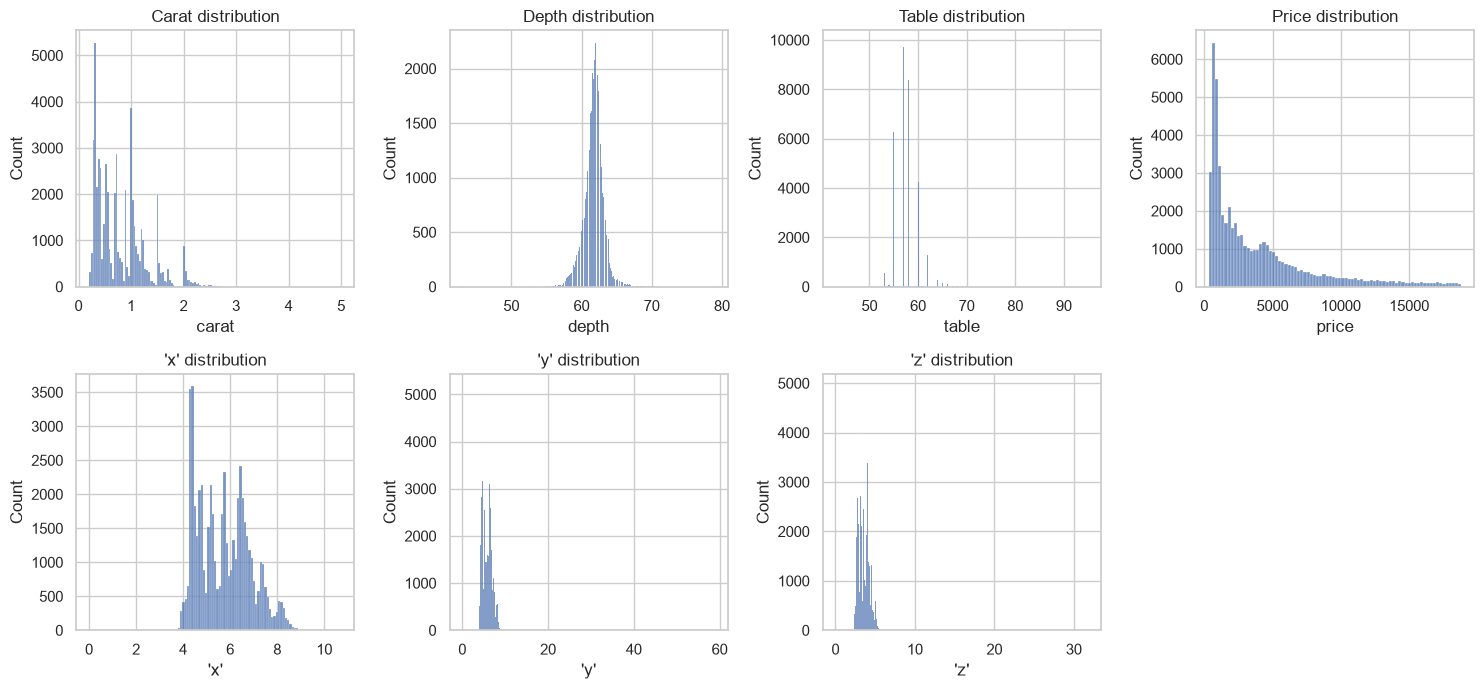

In [10]:
plt.figure(figsize=(15,10))
for i, col in enumerate(numeric_features, 1):
    plt.subplot(3, 4, i)
    sns.histplot(df[col], kde=False)
    plt.title(f"{col.capitalize()} distribution")

plt.tight_layout()
plt.show()


As we can see, there are some of the features that follow a charasteristic ditribution that can give us valuable information. For example, an easy one can be **price**. As we can see, it follows a lognormal distribution. This give us some information, such as noticing that there are much more cheap diamonds than expensive ones. This matches with the **carat** distribution, that confirms the theory, as there are much more diamonds with low carat than with high carat. 

This kinds of things are important in order to decide which model is the best, as some of them doesn't perform well with some kinds of distributions, or maybe some preprocessing is needed. 

#### Ordinal features

Now we can visualize ordinal features. It is important to remember that we have to define explicitly the order. 

In [11]:
# Select the ordinal features
ordinal_features = df.select_dtypes(include="str").columns.tolist()

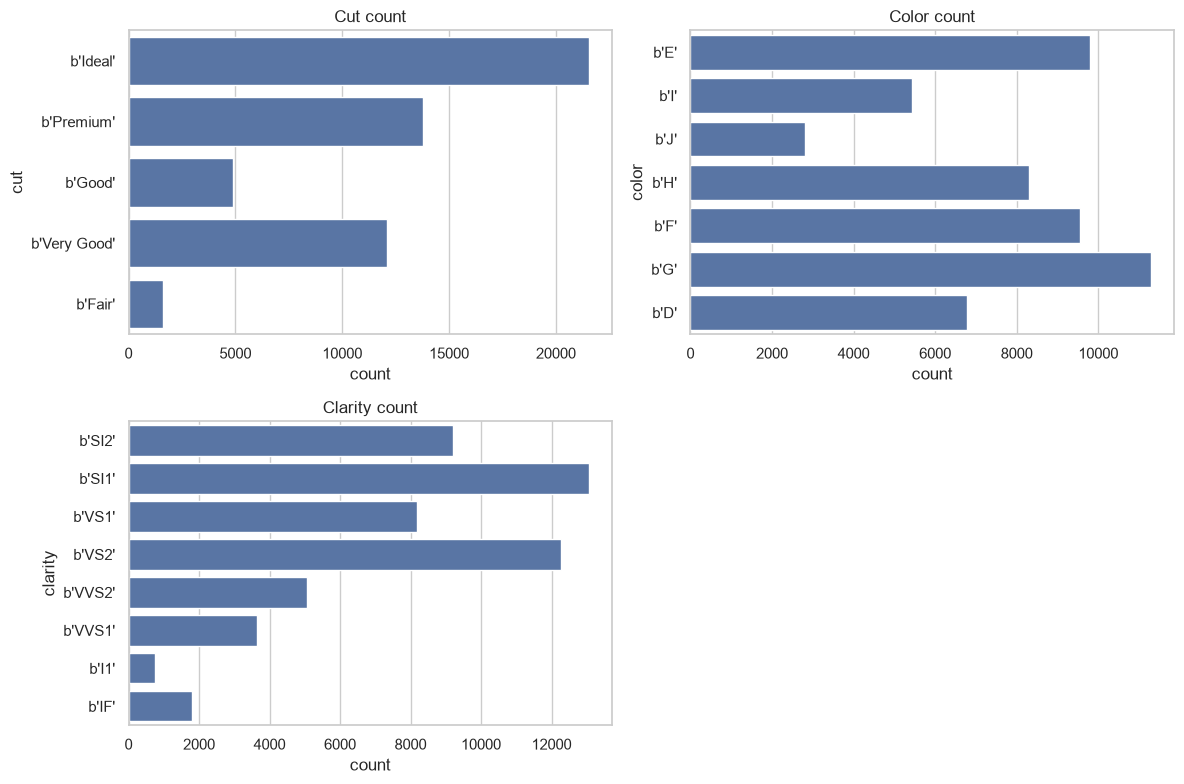

In [14]:
for i, col in enumerate(ordinal_features, 1):
    plt.subplot(2,2, i)
    sns.countplot(df[col])
    plt.title(f"{col.capitalize()} count")

plt.tight_layout()
plt.show()

Here we can notice, for example, that our target variable **cut** is imbalanced, as it has much more instances of ideal than fair. So we are going to see this as percentages

In [20]:
(df["cut"].value_counts(normalize=True) * 100).round(2)

cut
b'Ideal'        39.95
b'Premium'      25.57
b'Very Good'    22.40
b'Good'          9.10
b'Fair'          2.98
Name: proportion, dtype: float64

The different is considerable, but, if we look at the graphic above, we see that even the fair class with less than 3% is about 2000 instances aproximately. We will se later, but maybe it is not necessary to preprocess data for balancing classes. 

#### Outliers

Another important thing is to see the outliers. That means, values that are too far away from the rest of the values. 

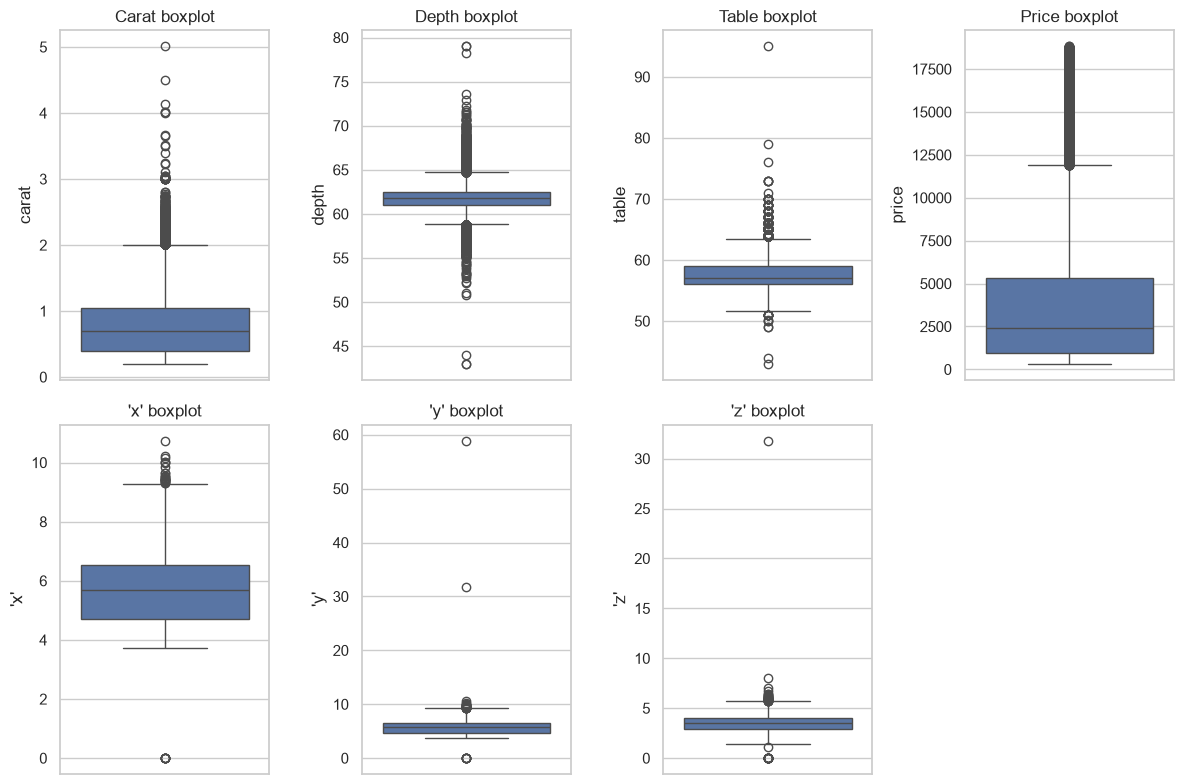

In [27]:
for i, col in enumerate(numeric_features, 1):
    plt.subplot(2,4, i)
    sns.boxplot(y=df[col])
    plt.title(f"{col.capitalize()} boxplot")

plt.tight_layout()
plt.show()

In [ ]:
INTERPRETAR LOS DATOS DE LA BOXPLOT